**Live Deployment Link:** https://YOUR-APP-NAME.streamlit.app/  
**GitHub Repo:** https://github.com/fa24-bcs-021-art/heart-disease-prediction

# Heart Disease Prediction System
**Course:** AIC354 Machine Learning Fundamentals | **Instructor:** Dr. Jawad Shafi | **Assignment 2**  
**Name:** Aryan Ali | **Roll No:** FA24-BCS-021

## Introduction
**Definition:** A binary classification task that predicts whether a patient has heart disease (Yes) or not (No) from a few simple health attributes.

**Application:** It can be used as a first screening tool and for learning how a full ML system is built, from data to deployment.

**Dataset:** Heart Disease dataset from UCI (https://archive.ics.uci.edu/dataset/45/heart+disease), Cleveland data (303 patients). The original dataset has 13 input attributes, but as per the assignment I selected only 4.

## Input and Output

| Input Attribute | Original column | Possible values |
|---|---|---|
| Age | age | Young (under 45), Middle (45 to 54), Senior (55 and above) |
| MaxHeartRate | thalach | Low (under 130), Medium (130 to 159), High (160 and above) |
| Sex | sex | Male, Female |
| ExerciseAngina | exang | Yes, No |

| Output | Possible values |
|---|---|
| HeartDisease | Yes, No |

**Why these 4 attributes?** Age and sex are basic patient info, maximum heart rate achieved and exercise induced angina are strong indicators in the dataset (patients with disease had a lower max heart rate and more exercise angina).

## Steps in this notebook
1. Import Libraries
2. Load Sample Data
3. Understand and Pre-process Sample Data
4. Feature Extraction
5. Label Encoding
6. Training Phase
7. Testing Phase
8. Application Phase
9. Feedback Phase
10. Deployment on the cloud

### Step 1: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import pickle
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import svm
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from prettytable import PrettyTable
import matplotlib.pyplot as plt
import seaborn as sns

### Step 2: Load Sample Data
`sample-data.csv` has the 4 selected inputs and the output, already converted from the UCI codes into readable text (for example sex 1 became Male, and age was grouped).

In [2]:
sample_data = pd.read_csv("sample-data.csv")

print("Sample Data (first 15 rows):")
print("============================\n")
print(sample_data.head(15))

Sample Data (first 15 rows):

       Age MaxHeartRate     Sex ExerciseAngina HeartDisease
0   Senior       Medium    Male             No           No
1    Young         High    Male             No           No
2    Young         High  Female             No           No
3   Senior         High    Male             No           No
4   Senior         High  Female            Yes           No
5   Senior       Medium    Male             No           No
6   Senior       Medium  Female             No           No
7    Young         High    Male             No           No
8   Middle         High    Male             No           No
9   Senior         High    Male             No           No
10  Middle         High    Male             No           No
11  Middle       Medium  Female             No           No
12  Middle         High    Male             No           No
13  Senior       Medium    Male            Yes           No
14  Senior         High  Female             No           No


### Step 3: Understand and Pre-process Sample Data
#### Step 3.1: Understand Sample Data

In [3]:
print("Attributes in Sample Data:")
print("==========================")
print(sample_data.columns)

print("\nNumber of Instances in Sample Data:", sample_data["Age"].count())

print("\nMissing values in each column:")
print(sample_data.isnull().sum())

print("\nOutput class distribution:")
print(sample_data["HeartDisease"].value_counts())

Attributes in Sample Data:
Index(['Age', 'MaxHeartRate', 'Sex', 'ExerciseAngina', 'HeartDisease'], dtype='str')

Number of Instances in Sample Data: 303

Missing values in each column:
Age               0
MaxHeartRate      0
Sex               0
ExerciseAngina    0
HeartDisease      0
dtype: int64

Output class distribution:
HeartDisease
No     165
Yes    138
Name: count, dtype: int64


#### Step 3.2: Pre-process Sample Data
The raw UCI file has 14 columns and numeric codes. Preprocessing already done to create `sample-data.csv`:
- Selected only 4 input attributes (age, thalach, sex, exang) and the output (num).
- Converted the output to Yes/No (any heart disease = Yes).
- Converted age and max heart rate into groups, and sex and exang codes into text.
- The 303 Cleveland rows have no missing values in these columns, so nothing was dropped.

#### Step 4: Feature Extraction
Features are already extracted (the 4 attributes above). No further feature extraction needed.

### Step 5: Label Encoding
#### Step 5.1: Train the Label Encoder

In [4]:
age = pd.DataFrame({"Age": ["Young", "Middle", "Senior"]})
heart_rate = pd.DataFrame({"MaxHeartRate": ["Low", "Medium", "High"]})
sex = pd.DataFrame({"Sex": ["Male", "Female"]})
angina = pd.DataFrame({"ExerciseAngina": ["Yes", "No"]})
disease = pd.DataFrame({"HeartDisease": ["Yes", "No"]})

age_label_encoder = LabelEncoder()
heart_rate_label_encoder = LabelEncoder()
sex_label_encoder = LabelEncoder()
angina_label_encoder = LabelEncoder()
disease_label_encoder = LabelEncoder()

age_label_encoder.fit(np.ravel(age))
heart_rate_label_encoder.fit(np.ravel(heart_rate))
sex_label_encoder.fit(np.ravel(sex))
angina_label_encoder.fit(np.ravel(angina))
disease_label_encoder.fit(np.ravel(disease))

print("Age classes:", age_label_encoder.classes_)
print("MaxHeartRate classes:", heart_rate_label_encoder.classes_)
print("Sex classes:", sex_label_encoder.classes_)
print("ExerciseAngina classes:", angina_label_encoder.classes_)
print("HeartDisease classes:", disease_label_encoder.classes_)

Age classes: ['Middle' 'Senior' 'Young']
MaxHeartRate classes: ['High' 'Low' 'Medium']
Sex classes: ['Female' 'Male']
ExerciseAngina classes: ['No' 'Yes']
HeartDisease classes: ['No' 'Yes']


#### Step 5.2: Label Encode the Output

In [5]:
sample_data_encoded_output = sample_data.copy()

sample_data["encoded_disease"] = disease_label_encoder.transform(sample_data["HeartDisease"])
print(sample_data[["HeartDisease", "encoded_disease"]].head(10))

sample_data_encoded_output["HeartDisease"] = sample_data["encoded_disease"]
sample_data_encoded_output.to_csv("sample-data-encoded-output.csv", index=False)
print("\nSaved: sample-data-encoded-output.csv")

  HeartDisease  encoded_disease
0           No                0
1           No                0
2           No                0
3           No                0
4           No                0
5           No                0
6           No                0
7           No                0
8           No                0
9           No                0

Saved: sample-data-encoded-output.csv


#### Step 5.3: Label Encode the Input

In [6]:
sample_data_encoded = sample_data_encoded_output.copy()

sample_data_encoded["Age"] = age_label_encoder.transform(sample_data_encoded_output["Age"])
sample_data_encoded["MaxHeartRate"] = heart_rate_label_encoder.transform(sample_data_encoded_output["MaxHeartRate"])
sample_data_encoded["Sex"] = sex_label_encoder.transform(sample_data_encoded_output["Sex"])
sample_data_encoded["ExerciseAngina"] = angina_label_encoder.transform(sample_data_encoded_output["ExerciseAngina"])

print("Sample Data after Label Encoding:")
print(sample_data_encoded.head(10))
sample_data_encoded.to_csv("sample-data-encoded.csv", index=False)

Sample Data after Label Encoding:
   Age  MaxHeartRate  Sex  ExerciseAngina  HeartDisease
0    1             2    1               0             0
1    2             0    1               0             0
2    2             0    0               0             0
3    1             0    1               0             0
4    1             0    0               1             0
5    1             2    1               0             0
6    1             2    0               0             0
7    2             0    1               0             0
8    0             0    1               0             0
9    1             0    1               0             0


### Step 6: Execute the Training Phase
#### Step 6.1: Split Sample Data into Training and Testing Data
80% for training and 20% for testing. I used `stratify` so both parts keep the same Yes/No ratio.

In [7]:
training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded,
    test_size=0.2,
    random_state=0,
    stratify=sample_data_encoded["HeartDisease"]
)

training_data_encoded.to_csv("training-data-encoded.csv", index=False)
testing_data_encoded.to_csv("testing-data-encoded.csv", index=False)

print("Training Data shape:", training_data_encoded.shape)
print("Testing Data shape:", testing_data_encoded.shape)

Training Data shape: (242, 5)
Testing Data shape: (61, 5)


#### Step 6.2: Split Input Vectors and Labels of Training Data

In [8]:
input_vector_train = training_data_encoded.iloc[:, :-1]
output_label_train = training_data_encoded.iloc[:, -1]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

Input vectors (train) shape: (242, 4)
Output labels (train) shape: (242,)


#### Step 6.3: Train the Support Vector Classifier
Same model as the Titanic notebook (SVC), so the steps stay exactly the same.

In [9]:
svc_model = svm.SVC(gamma="auto", random_state=0)
svc_model.fit(input_vector_train, np.ravel(output_label_train))
print(svc_model)

SVC(gamma='auto', random_state=0)


#### Step 6.4: Save the Trained Model

In [10]:
pickle.dump(svc_model, open("svc_heart_trained_model.pkl", "wb"))
print("Saved: svc_heart_trained_model.pkl")

Saved: svc_heart_trained_model.pkl


### Step 7: Execute the Testing Phase
#### Step 7.1: Split Input Vectors and Labels of Testing Data

In [11]:
input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (test) shape: (61, 4)
Output labels (test) shape: (61,)


#### Step 7.2: Load the Saved Model

In [12]:
loaded_model = pickle.load(open("svc_heart_trained_model.pkl", "rb"))
print("Model loaded successfully")

Model loaded successfully


#### Step 7.3: Evaluate the Model
##### Step 7.3.1: Make Predictions on Testing Data

In [13]:
predictions = loaded_model.predict(input_vector_test)

results = pd.DataFrame({
    "Actual": disease_label_encoder.inverse_transform(np.ravel(output_label_test)),
    "Predicted": disease_label_encoder.inverse_transform(predictions)
})
results.to_csv("model-predictions.csv", index=False)
print(results.head(15))

   Actual Predicted
0      No        No
1     Yes       Yes
2      No        No
3     Yes        No
4     Yes       Yes
5     Yes        No
6     Yes       Yes
7     Yes       Yes
8     Yes       Yes
9     Yes       Yes
10    Yes        No
11    Yes        No
12     No        No
13     No        No
14     No       Yes


#### Step 7.4: Calculate the Accuracy Score

In [14]:
accuracy = accuracy_score(output_label_test, predictions)
print("Accuracy on testing data:", round(accuracy, 4))

Accuracy on testing data: 0.7213


#### Step 7.5: Detailed Evaluation Metrics

              precision    recall  f1-score   support

          No       0.72      0.79      0.75        33
         Yes       0.72      0.64      0.68        28

    accuracy                           0.72        61
   macro avg       0.72      0.72      0.72        61
weighted avg       0.72      0.72      0.72        61



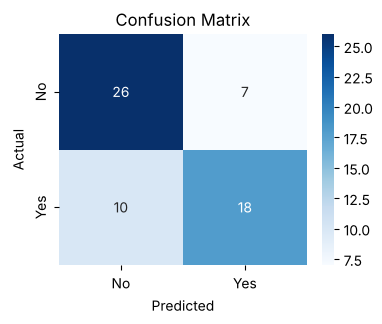

In [15]:
print(classification_report(output_label_test, predictions,
                            target_names=disease_label_encoder.classes_))

cm = confusion_matrix(output_label_test, predictions)
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=disease_label_encoder.classes_,
            yticklabels=disease_label_encoder.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

### Step 8: Execute the Application Phase
#### Step 8.1: Take Input from User
A sample patient is used here. In the deployed app the user picks these from dropdowns.

In [16]:
user_age = "Senior"
user_heart_rate = "Low"
user_sex = "Male"
user_angina = "Yes"

print("Patient details:")
print("Age:", user_age, "| MaxHeartRate:", user_heart_rate, "| Sex:", user_sex, "| ExerciseAngina:", user_angina)

Patient details:
Age: Senior | MaxHeartRate: Low | Sex: Male | ExerciseAngina: Yes


#### Step 8.2: Convert User Input into Feature Vector

In [17]:
feature_vector = pd.DataFrame({
    "Age": [user_age],
    "MaxHeartRate": [user_heart_rate],
    "Sex": [user_sex],
    "ExerciseAngina": [user_angina]
})
print(feature_vector)

      Age MaxHeartRate   Sex ExerciseAngina
0  Senior          Low  Male            Yes


#### Step 8.3: Label Encoding of Feature Vector

In [18]:
encoded_vector = pd.DataFrame({
    "Age": age_label_encoder.transform(feature_vector["Age"]),
    "MaxHeartRate": heart_rate_label_encoder.transform(feature_vector["MaxHeartRate"]),
    "Sex": sex_label_encoder.transform(feature_vector["Sex"]),
    "ExerciseAngina": angina_label_encoder.transform(feature_vector["ExerciseAngina"])
})
print(encoded_vector)

   Age  MaxHeartRate  Sex  ExerciseAngina
0    1             1    1               1


#### Step 8.4: Load the Saved Model

In [19]:
final_model = pickle.load(open("svc_heart_trained_model.pkl", "rb"))
print("Model loaded")

Model loaded


#### Step 8.5: Model Prediction
##### Step 8.5.1: Apply Model and Return Prediction to the User

In [20]:
prediction = final_model.predict(encoded_vector)
result = disease_label_encoder.inverse_transform(prediction)[0]

print("Predicted Heart Disease:", result)

Predicted Heart Disease: Yes


### Step 9: Execute the Feedback Phase
#### Step 9.1: Collect Feedback from Users and Domain Experts
Feedback I would collect from classmates and a medical domain expert:
- 4 inputs feels too few, a doctor would also want chest pain type, cholesterol and blood pressure.
- Grouping age and heart rate into 3 bands loses detail.
- Accuracy is around 70 to 75%, which is not enough for any real medical use.

#### Step 9.2: List of Potential Improvements
- Use more input attributes (chest pain type, blood pressure, cholesterol, ST depression).
- Use exact numeric age and heart rate instead of groups.
- Try other models (Logistic Regression, Random Forest) and compare.
- Use cross validation and a larger dataset (combine all 4 UCI sites).

#### Step 9.3: Improve the Model Based on Feedback
For this assignment the model is kept at 4 inputs because of the assignment constraint. With the above changes the model can be retrained and the app redeployed.

### Step 10: Deploy the Model on the Cloud
The trained model is deployed as a web app on Streamlit Community Cloud (code in a GitHub repo).

1. Create a GitHub repo and upload `app.py`, `svc_heart_trained_model.pkl`, `requirements.txt` and `runtime.txt`.
2. Sign in to https://share.streamlit.io with GitHub.
3. Click New app, choose the repo, branch `main` and main file `app.py`.
4. Click Deploy and wait for the build.
5. Copy the live link and paste it at the top of this notebook.

**Live link:** https://YOUR-APP-NAME.streamlit.app/